# Vehicle Insurance Cross-Sell — SHAP Explainability

This notebook explains the frozen weighted LightGBM model. It does not retrain, retune, or change the model. The model is loaded from MLflow, a representative sample is transformed through the saved preprocessing pipeline, and SHAP explanations are generated for global behavior and customers near the configurable top-10% outreach boundary.

Frozen model: `runs:/dc28826afdcc4e5cbce068db62439094/model`

SHAP explanations describe model behavior and contribution to the model score. They are not causal explanations and must not be used for claim approval, pricing, underwriting, eligibility, or adverse customer decisions.

## 1. Environment and reproducibility setup

The notebook uses the project environment and the existing `.env` file for MLflow credentials. SHAP must be installed in the notebook kernel before continuing. If the import cell reports that SHAP is missing, install the project dependency in the active environment and rerun the cell.

In [9]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split

try:
    import shap
except ImportError as shap_error:
    raise ImportError(
        "SHAP is required for this notebook. Install it in the active project environment, then rerun this cell."
    ) from shap_error

RANDOM_STATE = 42
FROZEN_MODEL_URI = "runs:/dc28826afdcc4e5cbce068db62439094/model"
TARGET_COLUMN = "Response"
ID_COLUMN = "id"
TOP_K_PERCENTAGE = 10
EXPLANATION_SAMPLE_SIZE = 5_000
BOUNDARY_WINDOW = 3

PROJECT_ROOT_CANDIDATES = [
    Path.cwd(),
    Path.cwd().parent,
]
PROJECT_ROOT = next(
    (
        candidate
        for candidate in PROJECT_ROOT_CANDIDATES
        if (candidate / "notebooks" / "data.csv").exists()
    ),
    Path.cwd(),
)
DATA_PATH = PROJECT_ROOT / "notebooks" / "data.csv"
SHAP_OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "shap_explainability"
SHAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

load_dotenv(PROJECT_ROOT / ".env")
tracking_uri = os.getenv("MLFLOW_TRACKING_URI")
if not tracking_uri:
    raise EnvironmentError("MLFLOW_TRACKING_URI is not configured. Check the project .env file.")
mlflow.set_tracking_uri(tracking_uri)

print(f"Project root: {PROJECT_ROOT}")
print(f"SHAP version: {shap.__version__}")
print(f"MLflow tracking URI configured: {tracking_uri}")
print(f"SHAP output directory: {SHAP_OUTPUT_DIR}")

Project root: d:\projVehicleInsurance\vehicle-Insurance
SHAP version: 0.52.0
MLflow tracking URI configured: https://dagshub.com/Youngboy01/vehicle-Insurance.mlflow
SHAP output directory: d:\projVehicleInsurance\vehicle-Insurance\artifacts\shap_explainability


In [10]:
FROZEN_MODEL_URI = "models:/m-3aacf46fc018452ab9aab96033eb7e56"

## 2. Load the frozen MLflow pipeline and raw dataset

The saved artifact contains both preprocessing and the LightGBM model. Loading the complete pipeline is important because SHAP must explain the same transformed features used during final evaluation. The raw dataset is used only to create explanation rows; no model fitting occurs here.

In [11]:
FROZEN_MODEL_URI = os.getenv("FROZEN_MODEL_URI")

if not FROZEN_MODEL_URI:
    raise EnvironmentError(
        "FROZEN_MODEL_URI is missing from the project .env file."
    )

In [12]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}")

frozen_pipeline = mlflow.sklearn.load_model(FROZEN_MODEL_URI)
raw_data = pd.read_csv(DATA_PATH)

required_columns = {TARGET_COLUMN, ID_COLUMN}
missing_required_columns = required_columns - set(raw_data.columns)
if missing_required_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_required_columns)}")

X_all = raw_data.drop(columns=[TARGET_COLUMN, ID_COLUMN]).reset_index(drop=True)
y_all = raw_data[TARGET_COLUMN].astype(int).reset_index(drop=True)
customer_ids = raw_data[ID_COLUMN].reset_index(drop=True)

if not set(y_all.unique()).issubset({0, 1}):
    raise ValueError("Response must contain only binary 0/1 labels.")

if not hasattr(frozen_pipeline, "named_steps"):
    raise TypeError("The MLflow artifact is not a scikit-learn pipeline with named steps.")

pipeline_step_names = list(frozen_pipeline.named_steps)
if "preprocessor" not in pipeline_step_names or "model" not in pipeline_step_names:
    raise KeyError(f"Expected preprocessor/model steps; found {pipeline_step_names}")

frozen_preprocessor = frozen_pipeline.named_steps["preprocessor"]
frozen_model = frozen_pipeline.named_steps["model"]
transformed_feature_names = [
    str(name)
    for name in frozen_preprocessor.get_feature_names_out()
]

print(f"Dataset rows: {len(X_all):,}")
print(f"Raw feature count: {X_all.shape[1]:,}")
print(f"Positive-response prevalence: {y_all.mean():.4%}")
print(f"Frozen pipeline steps: {pipeline_step_names}")
print(f"Transformed feature count: {len(transformed_feature_names):,}")

Dataset rows: 381,109
Raw feature count: 10
Positive-response prevalence: 12.2563%
Frozen pipeline steps: ['preprocessor', 'model']
Transformed feature count: 220


## 3. Build a representative explanation sample

A fixed stratified sample keeps runtime manageable while preserving the observed response prevalence. The complete raw dataset is also scored to identify customers immediately around the top-10% ranking boundary. These predictions are explanatory outputs only; they do not retrain or select a model.

In [13]:
sample_size = min(EXPLANATION_SAMPLE_SIZE, len(X_all) - 1)
_, X_explain, _, y_explain = train_test_split(
    X_all,
    y_all,
    test_size=sample_size,
    random_state=RANDOM_STATE,
    stratify=y_all,
)
X_explain = X_explain.reset_index(drop=True)
y_explain = y_explain.reset_index(drop=True)

all_scores = frozen_pipeline.predict_proba(X_all)[:, 1]
rank_order = np.argsort(-all_scores, kind="mergesort")
customer_rank = np.empty(len(all_scores), dtype=int)
customer_rank[rank_order] = np.arange(1, len(all_scores) + 1)
n_top_k = max(1, int(len(all_scores) * TOP_K_PERCENTAGE / 100))

boundary_positions = range(
    max(1, n_top_k - BOUNDARY_WINDOW),
    min(len(all_scores), n_top_k + BOUNDARY_WINDOW) + 1,
)
boundary_indices = [rank_order[position - 1] for position in boundary_positions]
boundary_table = X_all.iloc[boundary_indices].copy()
boundary_table.insert(0, ID_COLUMN, customer_ids.iloc[boundary_indices].to_numpy())
boundary_table["rank"] = customer_rank[boundary_indices]
boundary_table["score"] = all_scores[boundary_indices]
boundary_table["selected_at_top_10_percent"] = boundary_table["rank"] <= n_top_k
boundary_table = boundary_table.sort_values("rank").reset_index(drop=True)

print(f"Explanation rows: {len(X_explain):,}")
print(f"Explanation prevalence: {y_explain.mean():.4%}")
print(f"Top-{TOP_K_PERCENTAGE}% capacity: {n_top_k:,} customers")
display(boundary_table[[ID_COLUMN, "rank", "score", "selected_at_top_10_percent"]])

d:\projVehicleInsurance\vehicle-Insurance\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Explanation rows: 5,000
Explanation prevalence: 12.2600%
Top-10% capacity: 38,110 customers


,id,rank,score,selected_at_top_10_percent
0,163576,38107,0.792003,True
1,13915,38108,0.792002,True
2,37887,38109,0.792002,True
3,147563,38110,0.792002,True
4,196196,38111,0.792002,False
5,213064,38112,0.792001,False
6,338776,38113,0.791999,False


## 4. Transform explanation rows and calculate SHAP values

The final preprocessor is reused exactly as stored in MLflow. LightGBM receives the transformed dense matrix, while the original transformed feature names are retained for interpretation. The normalization helper handles SHAP versions that return either a positive-class array or a list of arrays.

In [14]:
def to_dense(matrix):
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

def positive_class_shap_values(explainer_output):
    if isinstance(explainer_output, list):
        return np.asarray(explainer_output[-1])
    output_array = np.asarray(explainer_output)
    if output_array.ndim == 3:
        return output_array[:, :, -1]
    return output_array

def positive_class_expected_value(expected_value):
    if isinstance(expected_value, (list, tuple, np.ndarray)):
        return float(np.asarray(expected_value).reshape(-1)[-1])
    return float(expected_value)

X_explain_transformed = to_dense(frozen_preprocessor.transform(X_explain))
if X_explain_transformed.shape[1] != len(transformed_feature_names):
    raise ValueError("Transformed matrix width does not match feature names.")

shap_explainer = shap.TreeExplainer(frozen_model)
shap_values = positive_class_shap_values(
    shap_explainer.shap_values(X_explain_transformed)
)
base_value = positive_class_expected_value(shap_explainer.expected_value)

if shap_values.shape != X_explain_transformed.shape:
    raise ValueError(
        f"SHAP shape {shap_values.shape} does not match transformed data shape {X_explain_transformed.shape}."
    )

raw_model_scores = frozen_model.predict(X_explain_transformed, raw_score=True)
additivity_error = np.max(
    np.abs(base_value + shap_values.sum(axis=1) - raw_model_scores)
)

print(f"SHAP matrix shape: {shap_values.shape}")
print(f"SHAP base value in raw model-output space: {base_value:.6f}")
print(f"Maximum SHAP additivity error: {additivity_error:.8f}")

d:\projVehicleInsurance\vehicle-Insurance\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
d:\projVehicleInsurance\vehicle-Insurance\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


SHAP matrix shape: (5000, 220)
SHAP base value in raw model-output space: -2.478129
Maximum SHAP additivity error: 0.00000000


## 5. Global SHAP importance and visualizations

The bar plot ranks transformed features by mean absolute SHAP value. The beeswarm plot additionally shows direction: points to the right push the score higher, while points to the left push it lower. These are model-level patterns across the explanation sample.

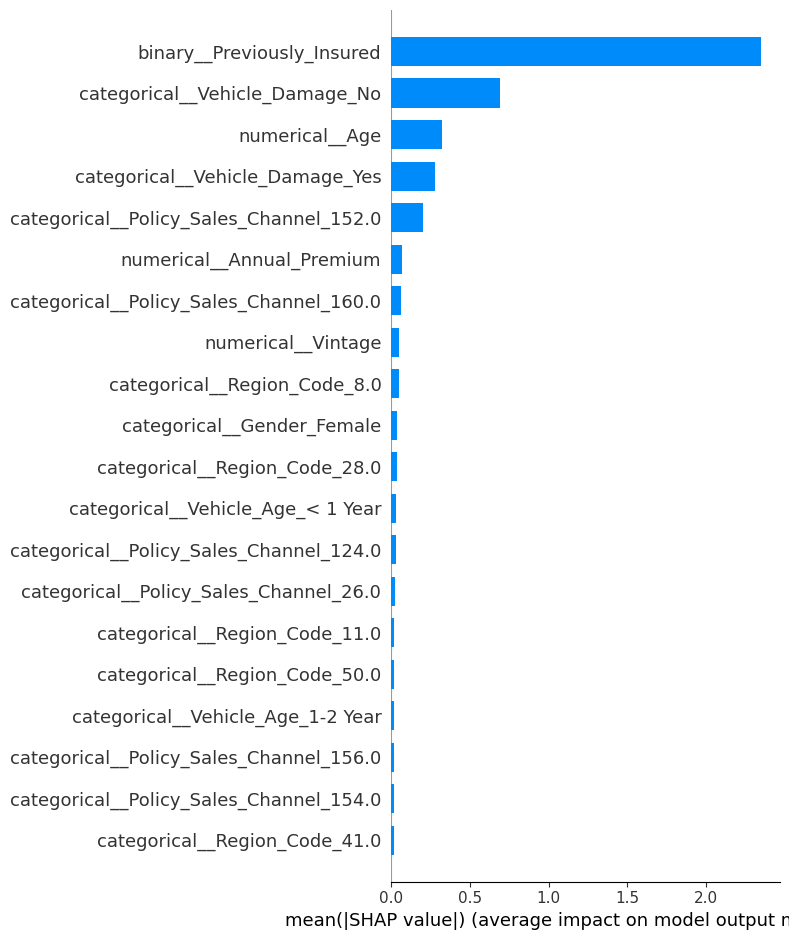

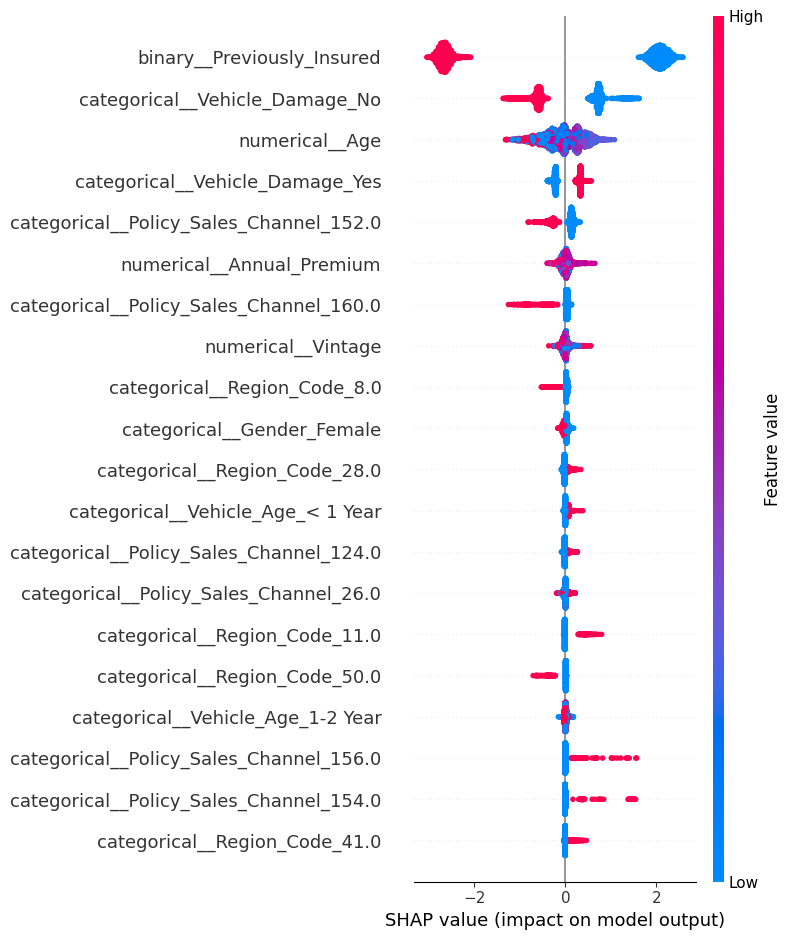

,transformed_feature,mean_abs_shap
0,binary__Previously_Insured,2.350207
1,categorical__Vehicle_Damage_No,0.693229
2,numerical__Age,0.326053
3,categorical__Vehicle_Damage_Yes,0.275759
4,categorical__Policy_Sales_Channel_152.0,0.202202
5,numerical__Annual_Premium,0.068790
6,categorical__Policy_Sales_Channel_160.0,0.064710
7,numerical__Vintage,0.052964
8,categorical__Region_Code_8.0,0.047683
9,categorical__Gender_Female,0.039821


In [15]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
global_shap_importance = (
    pd.DataFrame({
        "transformed_feature": transformed_feature_names,
        "mean_abs_shap": mean_abs_shap,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

global_bar_path = SHAP_OUTPUT_DIR / "global_shap_bar.png"
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_explain_transformed,
    feature_names=transformed_feature_names,
    plot_type="bar",
    max_display=20,
    show=False,
)
plt.tight_layout()
plt.savefig(global_bar_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

beeswarm_path = SHAP_OUTPUT_DIR / "global_shap_beeswarm.png"
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_explain_transformed,
    feature_names=transformed_feature_names,
    max_display=20,
    show=False,
)
plt.tight_layout()
plt.savefig(beeswarm_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

display(global_shap_importance.head(20))

## 6. Group encoded SHAP values back to raw business features

One-hot encoding creates multiple transformed columns for a single raw feature. This section aggregates them back to raw features such as `Region_Code` and `Policy_Sales_Channel`, so the result is suitable for the model card and business discussion. Global grouped importance uses the sum of mean absolute SHAP values across the encoded columns in each raw group.

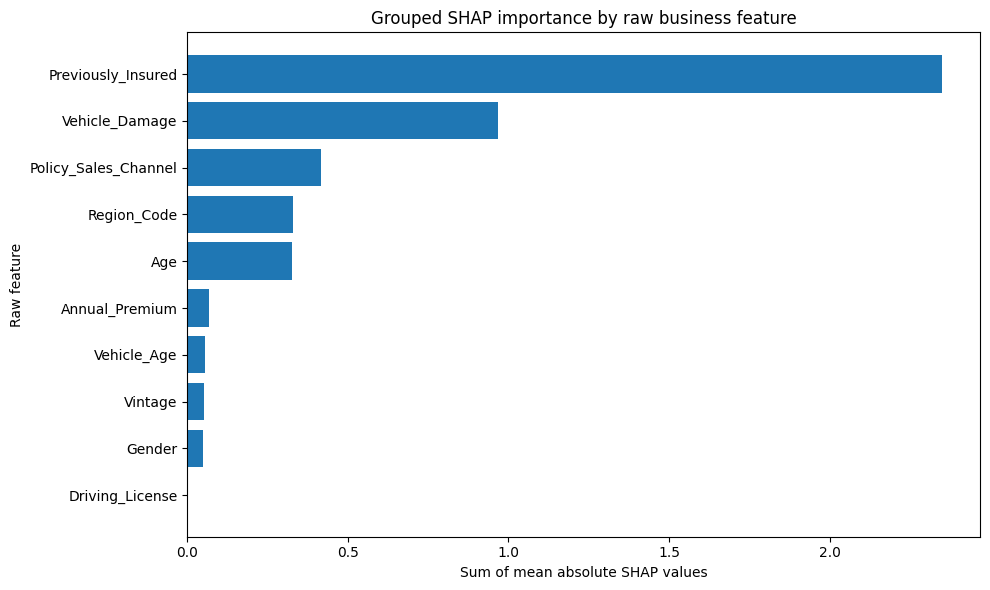

,raw_feature,mean_abs_shap_contribution
0,Previously_Insured,2.350207
1,Vehicle_Damage,0.968988
2,Policy_Sales_Channel,0.416180
3,Region_Code,0.329538
4,Age,0.326053
5,Annual_Premium,0.068790
6,Vehicle_Age,0.054724
7,Vintage,0.052964
8,Gender,0.050113
9,Driving_License,0.003009


In [16]:
raw_feature_names = [str(column) for column in X_all.columns]

def map_transformed_to_raw(transformed_name):
    feature_tail = transformed_name.split("__", 1)[-1]
    for raw_name in sorted(raw_feature_names, key=len, reverse=True):
        if feature_tail == raw_name or feature_tail.startswith(f"{raw_name}_"):
            return raw_name
    return feature_tail

transformed_to_raw = {
    name: map_transformed_to_raw(name)
    for name in transformed_feature_names
}
raw_group_labels = [transformed_to_raw[name] for name in transformed_feature_names]

grouped_shap_importance = (
    pd.DataFrame({
        "raw_feature": raw_group_labels,
        "mean_abs_shap_contribution": mean_abs_shap,
    })
    .groupby("raw_feature", as_index=False)["mean_abs_shap_contribution"]
    .sum()
    .sort_values("mean_abs_shap_contribution", ascending=False)
    .reset_index(drop=True)
)

grouped_bar_path = SHAP_OUTPUT_DIR / "grouped_raw_feature_shap.png"
plot_data = grouped_shap_importance.sort_values("mean_abs_shap_contribution")
plt.figure(figsize=(10, 6))
plt.barh(plot_data["raw_feature"], plot_data["mean_abs_shap_contribution"])
plt.xlabel("Sum of mean absolute SHAP values")
plt.ylabel("Raw feature")
plt.title("Grouped SHAP importance by raw business feature")
plt.tight_layout()
plt.savefig(grouped_bar_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

display(grouped_shap_importance)

## 7. Numeric-feature dependence plots

Dependence plots show how the model contribution changes as a numeric feature changes. The code checks for the transformed numeric column dynamically because the preprocessor may prefix feature names. These plots describe learned association and should not be interpreted as causal effects.

<Figure size 900x600 with 0 Axes>

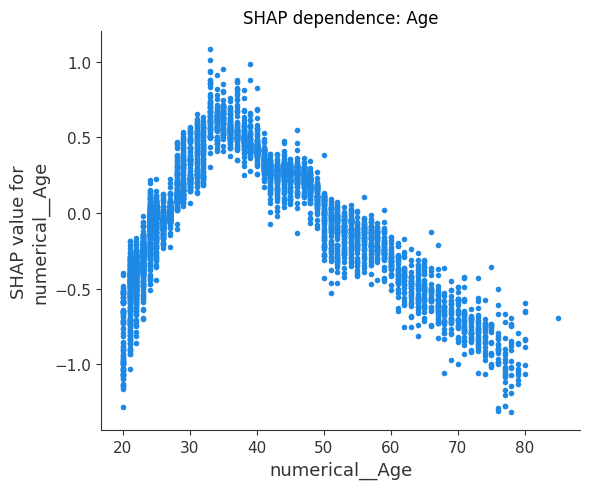

<Figure size 900x600 with 0 Axes>

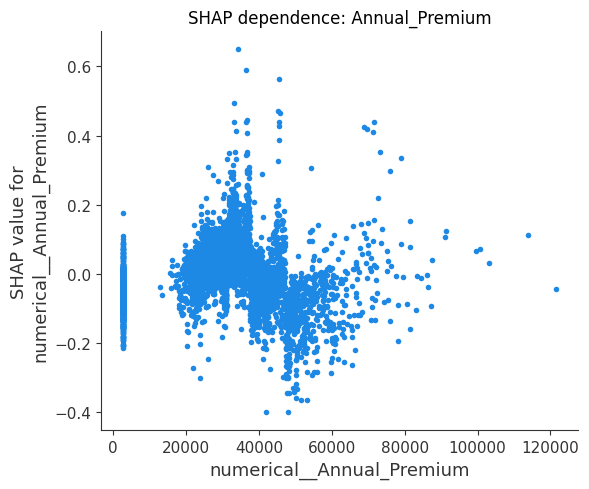

<Figure size 900x600 with 0 Axes>

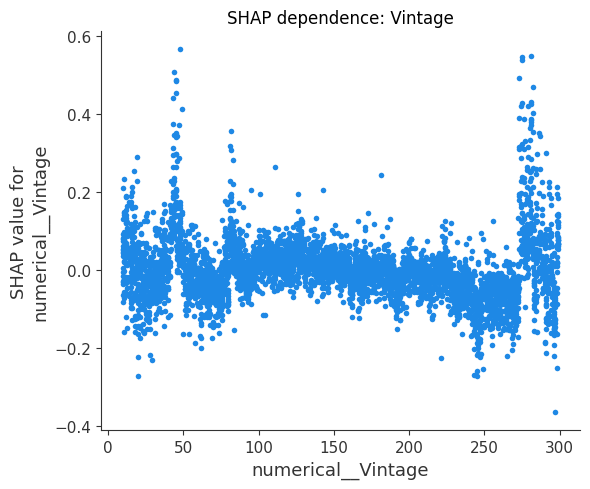

Dependence plots saved:


,raw_feature,path
0,Age,d:\projVehicleInsurance\vehicle-Insurance\arti...
1,Annual_Premium,d:\projVehicleInsurance\vehicle-Insurance\arti...
2,Vintage,d:\projVehicleInsurance\vehicle-Insurance\arti...


In [17]:
def transformed_index_for_raw_feature(raw_feature):
    candidates = [
        index
        for index, name in enumerate(transformed_feature_names)
        if name == raw_feature or name.endswith(f"__{raw_feature}")
    ]
    return candidates[0] if candidates else None

dependence_paths = {}
for raw_feature in ["Age", "Annual_Premium", "Vintage"]:
    feature_index = transformed_index_for_raw_feature(raw_feature)
    if feature_index is None:
        print(f"Skipping dependence plot; transformed feature not found: {raw_feature}")
        continue
    output_path = SHAP_OUTPUT_DIR / f"dependence_{raw_feature}.png"
    plt.figure(figsize=(9, 6))
    shap.dependence_plot(
        feature_index,
        shap_values,
        X_explain_transformed,
        feature_names=transformed_feature_names,
        interaction_index=None,
        show=False,
    )
    plt.title(f"SHAP dependence: {raw_feature}")
    plt.tight_layout()
    plt.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
    dependence_paths[raw_feature] = str(output_path)

print("Dependence plots saved:")
display(pd.DataFrame({"raw_feature": list(dependence_paths), "path": list(dependence_paths.values())}))

## 8. Local explanations near the top-10% boundary

Customers immediately above and below the top-10% boundary are operationally important. A small score or ranking change can determine whether they are contacted. This section creates a boundary table, transformed-feature waterfall plots, and grouped raw-feature contribution tables for those customers.

d:\projVehicleInsurance\vehicle-Insurance\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


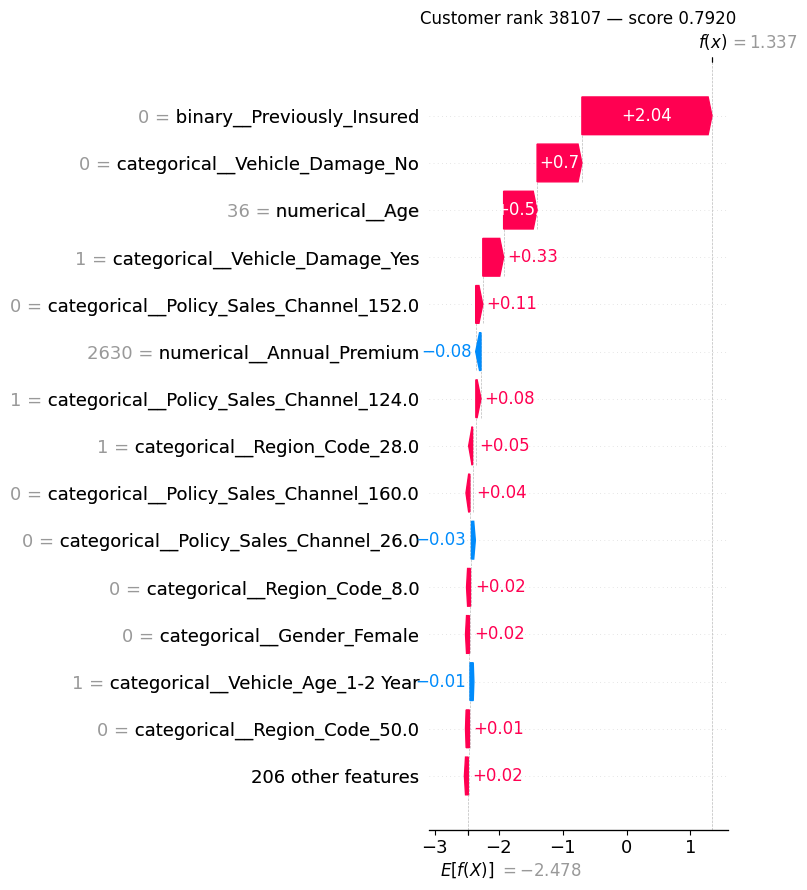

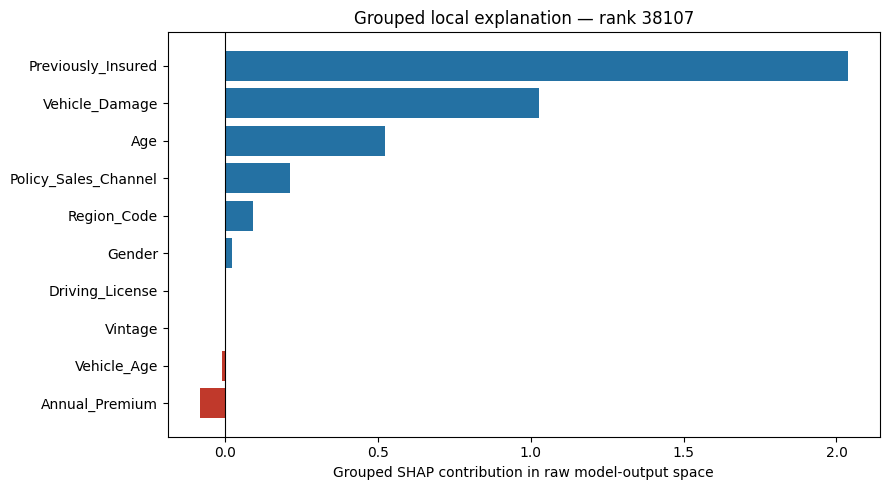

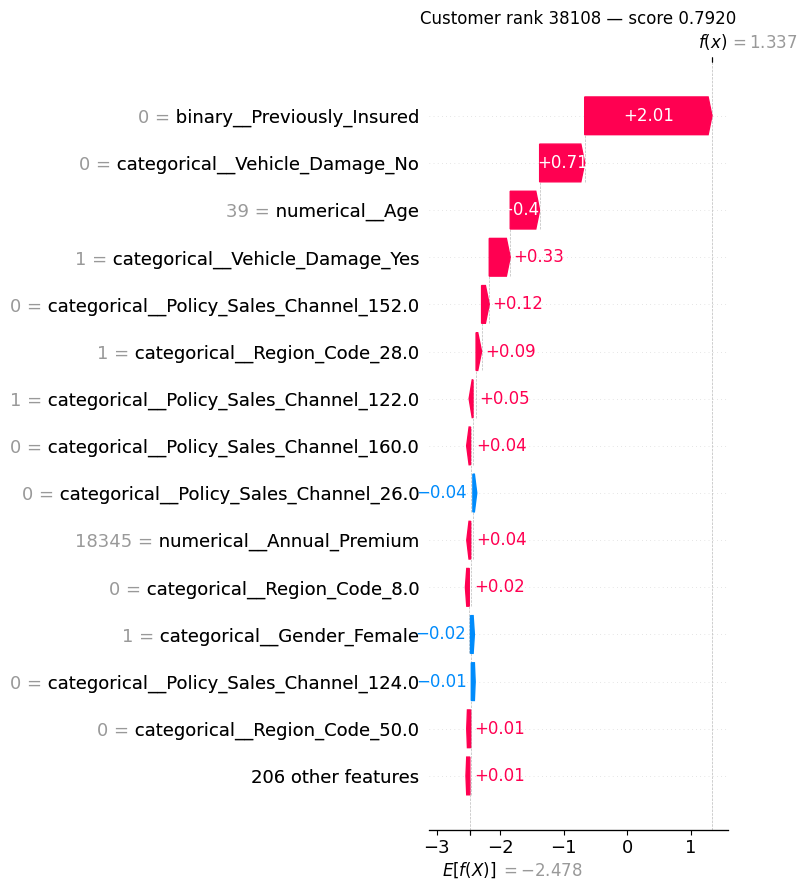

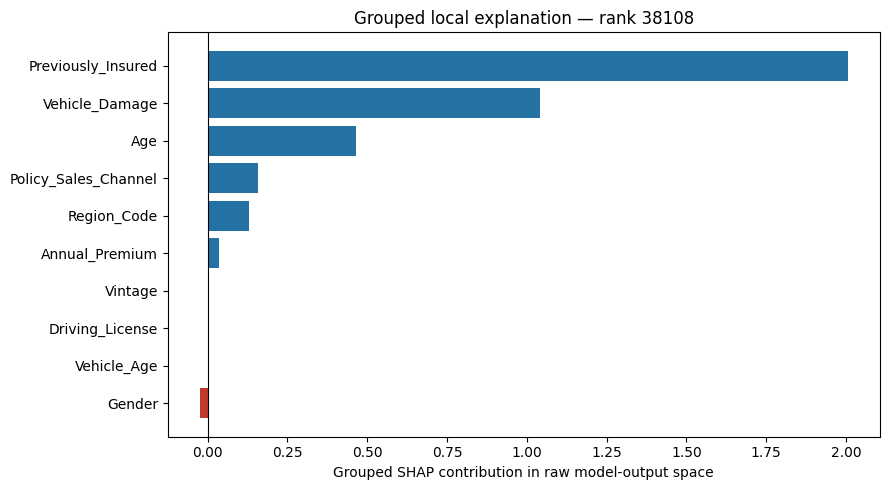

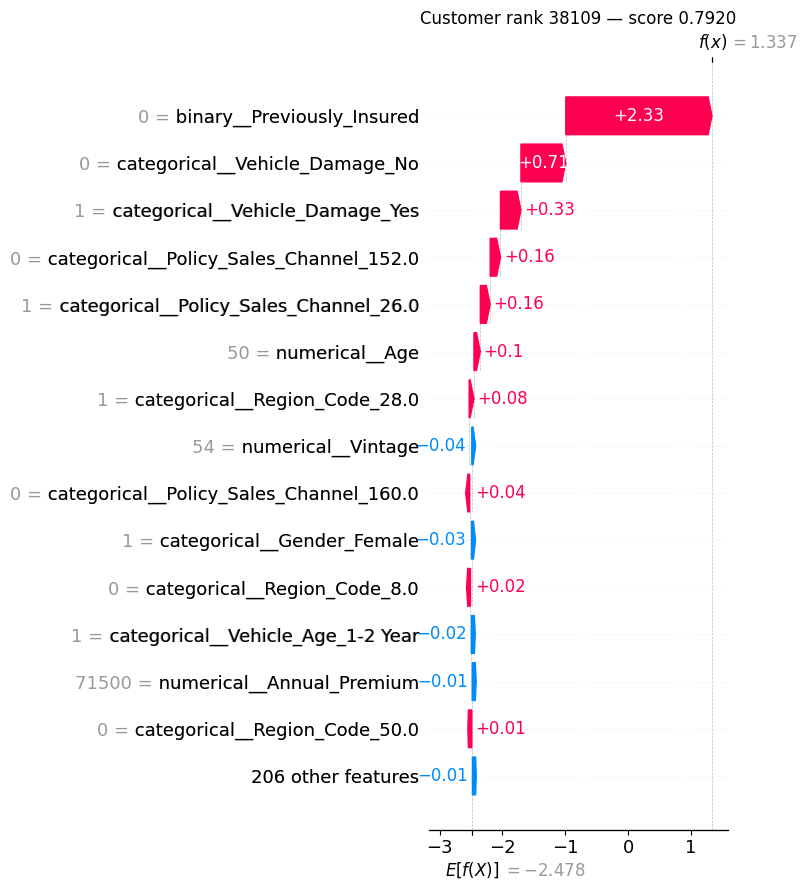

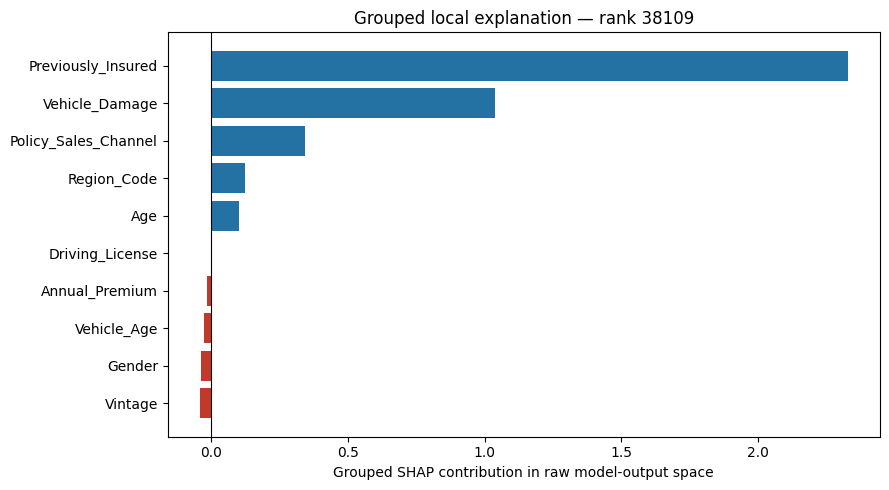

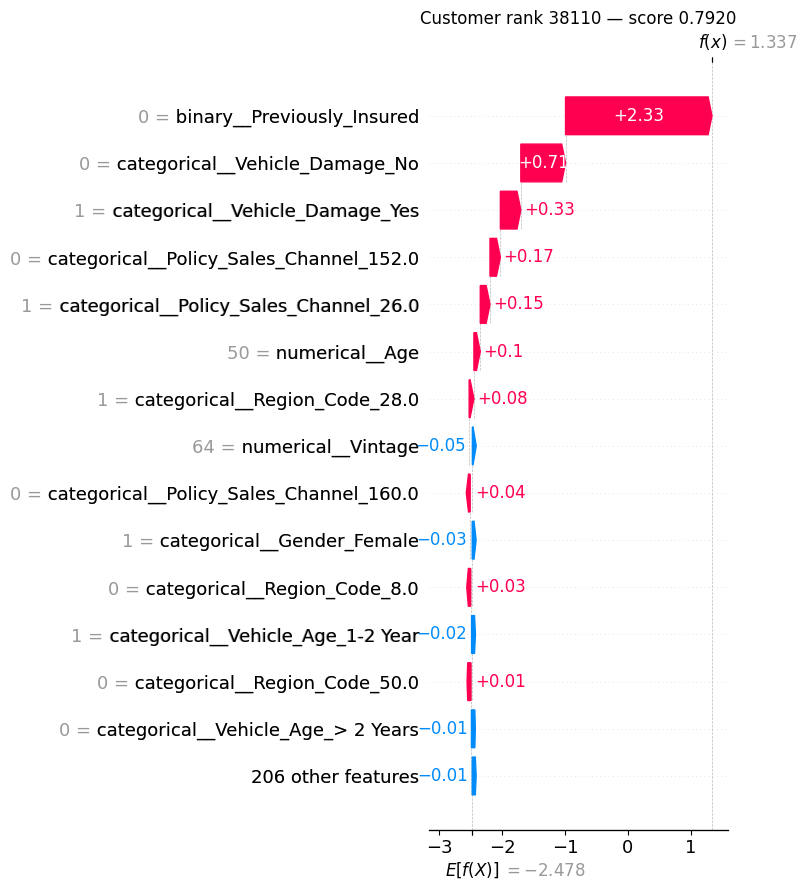

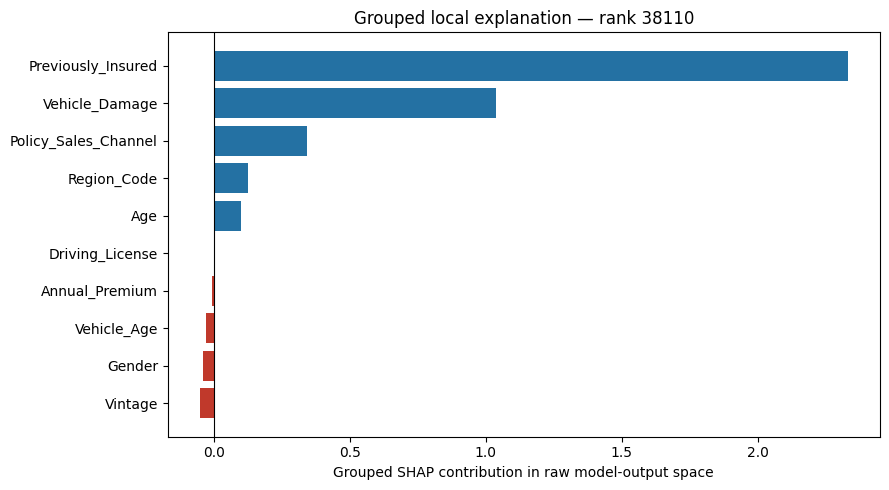

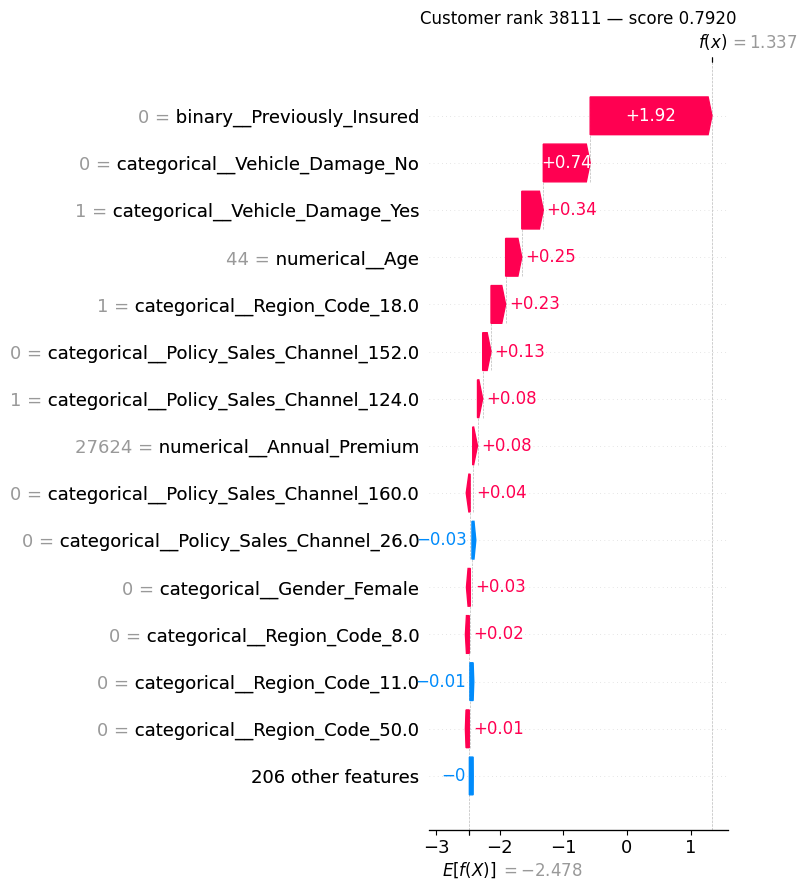

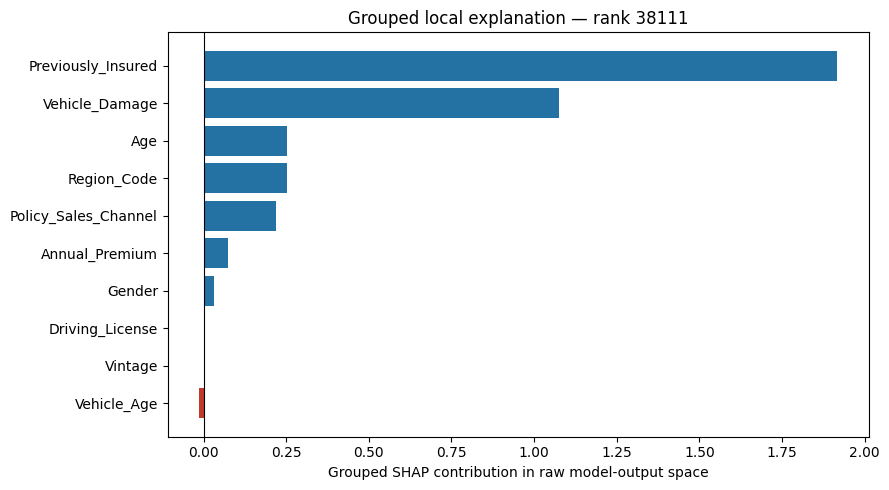

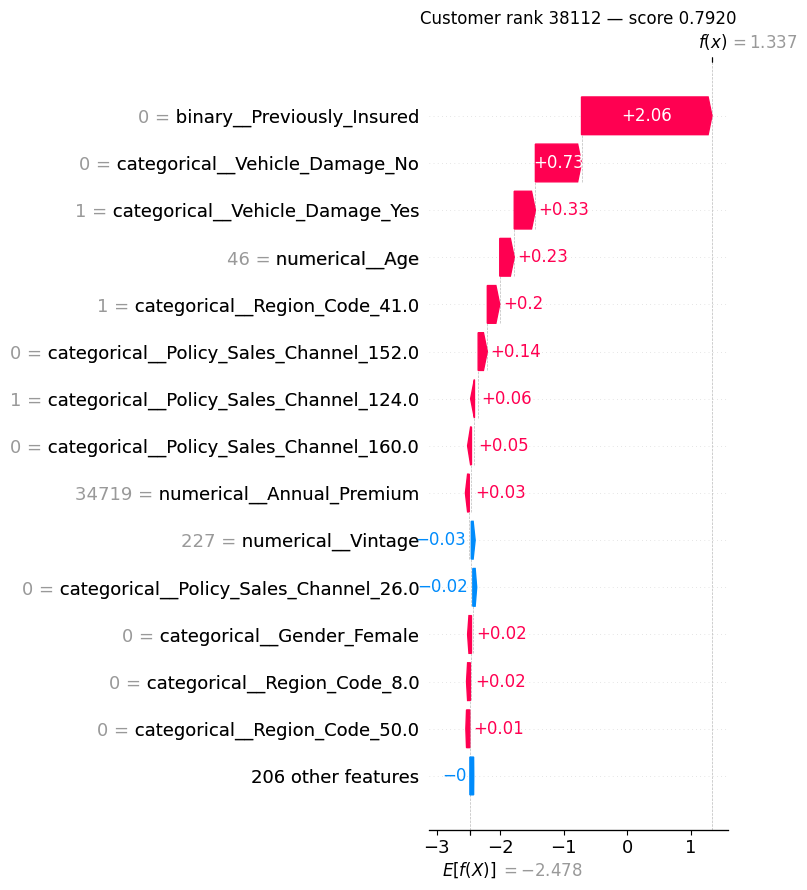

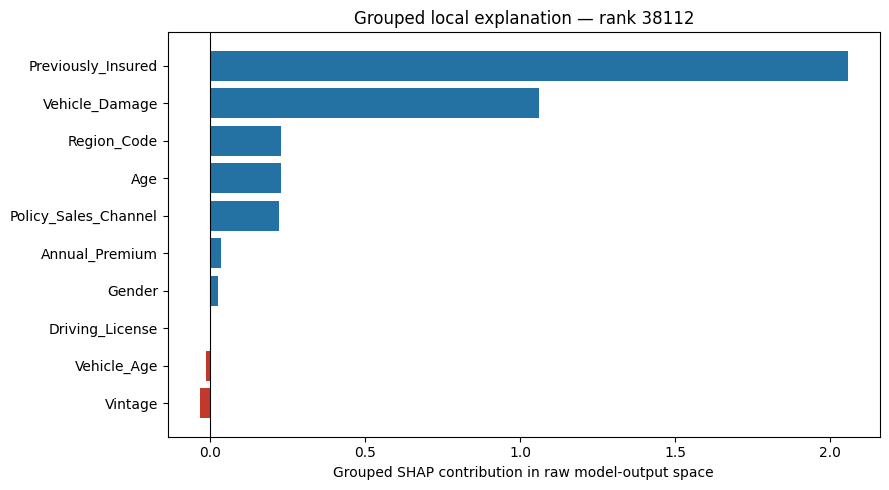

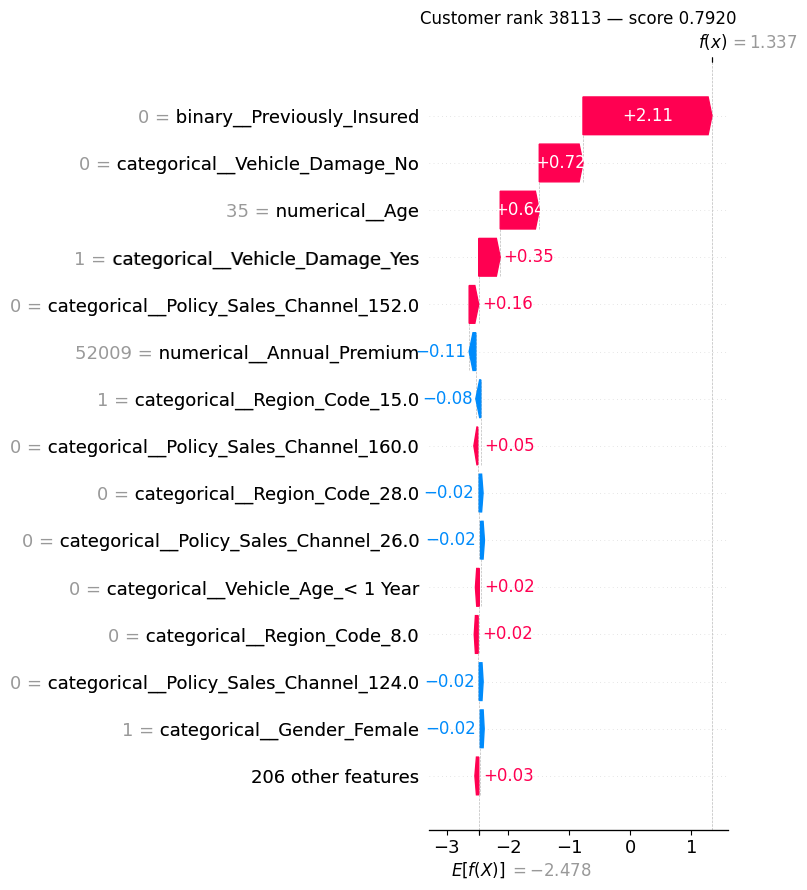

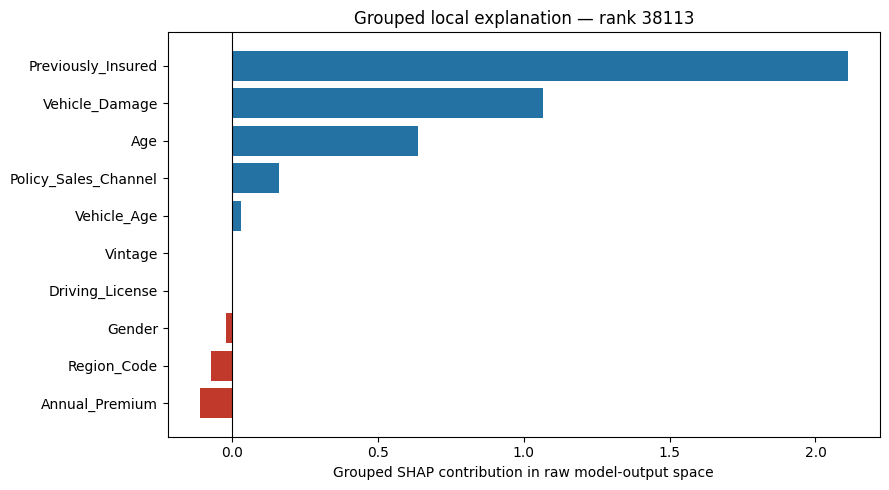

,id,rank,score,selected_at_top_10_percent,strongest_positive_raw_feature,strongest_positive_shap,strongest_negative_raw_feature,strongest_negative_shap
0,163576,38107,0.792003,True,Previously_Insured,2.036467,Annual_Premium,-0.082878
1,13915,38108,0.792002,True,Previously_Insured,2.005331,Gender,-0.024118
2,37887,38109,0.792002,True,Previously_Insured,2.328876,Vintage,-0.041767
3,147563,38110,0.792002,True,Previously_Insured,2.330515,Vintage,-0.051288
4,196196,38111,0.792002,False,Previously_Insured,1.915539,Vehicle_Age,-0.012231
5,213064,38112,0.792001,False,Previously_Insured,2.056107,Vintage,-0.031935
6,338776,38113,0.791999,False,Previously_Insured,2.110185,Annual_Premium,-0.108998


In [18]:
X_boundary = X_all.iloc[boundary_indices].reset_index(drop=True)
X_boundary_transformed = to_dense(frozen_preprocessor.transform(X_boundary))
boundary_shap_values = positive_class_shap_values(
    shap_explainer.shap_values(X_boundary_transformed)
)

def grouped_local_contributions(local_values):
    return (
        pd.DataFrame({
            "raw_feature": raw_group_labels,
            "shap_value": local_values,
        })
        .groupby("raw_feature", as_index=False)["shap_value"]
        .sum()
        .sort_values("shap_value")
    )

local_explanation_records = []
for local_index, original_index in enumerate(boundary_indices):
    local_values = boundary_shap_values[local_index]
    grouped_local = grouped_local_contributions(local_values)
    strongest_positive = grouped_local.iloc[-1]
    strongest_negative = grouped_local.iloc[0]
    local_explanation_records.append({
        ID_COLUMN: str(customer_ids.iloc[original_index]),
        "rank": int(customer_rank[original_index]),
        "score": float(all_scores[original_index]),
        "selected_at_top_10_percent": bool(customer_rank[original_index] <= n_top_k),
        "strongest_positive_raw_feature": str(strongest_positive["raw_feature"]),
        "strongest_positive_shap": float(strongest_positive["shap_value"]),
        "strongest_negative_raw_feature": str(strongest_negative["raw_feature"]),
        "strongest_negative_shap": float(strongest_negative["shap_value"]),
    })

    local_explanation = shap.Explanation(
        values=local_values,
        base_values=base_value,
        data=X_boundary_transformed[local_index],
        feature_names=transformed_feature_names,
    )
    waterfall_path = SHAP_OUTPUT_DIR / f"waterfall_rank_{int(customer_rank[original_index])}.png"
    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(local_explanation, max_display=15, show=False)
    plt.title(
        f"Customer rank {int(customer_rank[original_index])} — score {all_scores[original_index]:.4f}"
    )
    plt.tight_layout()
    plt.savefig(waterfall_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    local_plot_data = pd.concat([grouped_local.head(5), grouped_local.tail(5)])
    local_plot_data = local_plot_data.drop_duplicates(subset=["raw_feature"]).sort_values("shap_value")
    local_bar_path = SHAP_OUTPUT_DIR / f"grouped_local_rank_{int(customer_rank[original_index])}.png"
    plt.figure(figsize=(9, 5))
    colors = ["#c0392b" if value < 0 else "#2471a3" for value in local_plot_data["shap_value"]]
    plt.barh(local_plot_data["raw_feature"], local_plot_data["shap_value"], color=colors)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Grouped SHAP contribution in raw model-output space")
    plt.title(f"Grouped local explanation — rank {int(customer_rank[original_index])}")
    plt.tight_layout()
    plt.savefig(local_bar_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

local_explanation_records = pd.DataFrame(local_explanation_records)
local_explanation_records_path = SHAP_OUTPUT_DIR / "boundary_local_explanations.csv"
local_explanation_records.to_csv(local_explanation_records_path, index=False)
display(local_explanation_records)

## 9. Log SHAP artifacts and explanation records to MLflow

All generated plots, grouped importance tables, boundary explanations, and reproducibility metadata are logged under a separate MLflow run. This run references the frozen model but does not create a new model version.

In [19]:
global_shap_importance_path = SHAP_OUTPUT_DIR / "global_shap_importance.csv"
grouped_shap_importance_path = SHAP_OUTPUT_DIR / "grouped_raw_feature_shap_importance.csv"
boundary_table_path = SHAP_OUTPUT_DIR / "top_10_boundary_customers.csv"
global_shap_importance.to_csv(global_shap_importance_path, index=False)
grouped_shap_importance.to_csv(grouped_shap_importance_path, index=False)
boundary_table.to_csv(boundary_table_path, index=False)

if mlflow.active_run() is not None:
    mlflow.end_run(status="KILLED")

with mlflow.start_run(run_name="shap_explainability_frozen_lgbm") as shap_run:
    shap_run_id = shap_run.info.run_id
    mlflow.set_tags({
        "stage": "post_freeze_explainability",
        "source_model_run_id": "dc28826afdcc4e5cbce068db62439094",
        "model_uri": FROZEN_MODEL_URI,
        "explanation_type": "TreeSHAP_global_grouped_local",
        "test_set_used_for_model_selection": "false",
    })
    mlflow.log_params({
        "source_model_run_id": "dc28826afdcc4e5cbce068db62439094",
        "explanation_sample_size": len(X_explain),
        "explanation_sample_random_state": RANDOM_STATE,
        "top_k_percentage": TOP_K_PERCENTAGE,
        "boundary_window": BOUNDARY_WINDOW,
        "transformed_feature_count": len(transformed_feature_names),
    })
    mlflow.log_metrics({
        "shap_max_additivity_error": float(additivity_error),
        "mean_abs_shap_top_feature": float(global_shap_importance.iloc[0]["mean_abs_shap"]),
        "grouped_shap_top_feature": float(grouped_shap_importance.iloc[0]["mean_abs_shap_contribution"]),
    })
    mlflow.log_text(
        json.dumps({
            "source_model_uri": FROZEN_MODEL_URI,
            "source_model_run_id": "dc28826afdcc4e5cbce068db62439094",
            "sample_rows": len(X_explain),
            "sample_positive_rate": float(y_explain.mean()),
            "top_k_percentage": TOP_K_PERCENTAGE,
            "base_value_raw_model_output": base_value,
            "max_additivity_error": float(additivity_error),
        }, indent=2),
        artifact_file="shap_run_metadata.json",
    )
    for artifact_path in [
        global_bar_path,
        beeswarm_path,
        grouped_bar_path,
        global_shap_importance_path,
        grouped_shap_importance_path,
        boundary_table_path,
        local_explanation_records_path,
    ]:
        mlflow.log_artifact(str(artifact_path))
    for dependence_path in dependence_paths.values():
        mlflow.log_artifact(dependence_path)
    for waterfall_path in SHAP_OUTPUT_DIR.glob("waterfall_rank_*.png"):
        mlflow.log_artifact(str(waterfall_path))
    for local_bar_path in SHAP_OUTPUT_DIR.glob("grouped_local_rank_*.png"):
        mlflow.log_artifact(str(local_bar_path))

print(f"SHAP MLflow run ID: {shap_run_id}")
print(f"Local SHAP artifacts: {SHAP_OUTPUT_DIR}")

🏃 View run shap_explainability_frozen_lgbm at: https://dagshub.com/Youngboy01/vehicle-Insurance.mlflow/#/experiments/0/runs/9a3d12ac156c48dda5a0a1e6a0b1d45f
🧪 View experiment at: https://dagshub.com/Youngboy01/vehicle-Insurance.mlflow/#/experiments/0
SHAP MLflow run ID: 9a3d12ac156c48dda5a0a1e6a0b1d45f
Local SHAP artifacts: d:\projVehicleInsurance\vehicle-Insurance\artifacts\shap_explainability


## 10. Model-card update

The observed global rankings, grouped raw-feature directions, additivity check, and boundary-customer findings have been reviewed and recorded in `docs/model_card.md`. The model card states that SHAP explains association in the frozen model and does not establish causal campaign impact.

## 11. SHAP findings and interpretation

### Analysis validity

The frozen MLflow pipeline loaded successfully. The explanation sample contains `5,000` rows with `12.2600%` positive responses, closely matching the full-data prevalence of `12.2563%`. The transformed SHAP matrix has shape `(5,000, 220)`. The maximum TreeSHAP additivity error is `0.00000000`, so the SHAP contributions reconcile with the LightGBM raw model output for the sampled rows. The SHAP values are in the model's raw output space, not percentage points; they describe movement from the model baseline before the output is converted into a response score.

The LightGBM and SHAP warnings are non-blocking. The feature-name warning is caused by passing the transformed numeric matrix to the fitted LightGBM model; the model and SHAP dimensions are correct. The SHAP warning reflects the library's change in binary-classifier output format, which the notebook's positive-class normalization handles explicitly.

### Global feature behavior

`Previously_Insured` is by far the dominant raw feature, with grouped mean absolute SHAP contribution `2.350207`. It is substantially larger than `Vehicle_Damage` (`0.968988`), `Policy_Sales_Channel` (`0.416180`), `Region_Code` (`0.329538`), and `Age` (`0.326053`). The encoded-feature plot shows the same pattern: the binary `Previously_Insured` column dominates the model output contribution.

The beeswarm direction indicates that `Previously_Insured = 0` generally pushes the response score upward, while `Previously_Insured = 1` pushes it strongly downward. This is a coherent marketing-response pattern: customers without an existing vehicle-insurance policy are more likely to be prospects for a cross-sell offer. It is still an association learned from historical data, not evidence that removing insurance causes a response.

`Vehicle_Damage` is the second major driver. The `Vehicle_Damage_Yes` encoding generally pushes scores upward and `Vehicle_Damage_No` generally pushes them downward. This agrees with the earlier feature ablation and permutation results and provides a clear reason why the feature must remain in the model.

`Policy_Sales_Channel` and `Region_Code` have meaningful grouped importance even though their individual one-hot levels are spread across many encoded columns. This supports retaining both features. Their values should be treated as categorical business codes, not as continuous numeric measurements. SHAP also shows that their effects are level-specific rather than one simple monotonic direction.

`Age` has moderate global importance, but its dependence plot reveals a nonlinear inverted-U pattern. SHAP contribution is generally positive around the mid-30s to early-40s and becomes increasingly negative at older ages, especially after approximately 50. The model is therefore not using age as a simple older-is-better or younger-is-better rule.

`Annual_Premium` has modest importance and a dispersed, non-monotonic dependence pattern. The model does not assign one consistent direction to higher premiums across all customers. `Vintage` has low global importance and a noisy, irregular dependence pattern, which is consistent with the earlier ablation finding that it adds little incremental ranking signal.

`Gender` has low grouped contribution and `Driving_License` is nearly negligible. Their low SHAP importance is consistent with the leave-one-feature-out experiments. Low importance does not automatically prove absence of bias, so a separate segment-level performance/fairness review would still be needed before production use.

### Boundary-customer analysis

The top-10% capacity contains `38,110` of `381,109` customers. The last selected customer has rank `38,110` and score approximately `0.7920018434`; the first unselected customer has rank `38,111` and score approximately `0.7920017617`. The difference is approximately `0.0000000817`, so the boundary distinction is operationally negligible even though the deterministic ranking must place one customer on each side.

This means the model is confident about the broad high-score group, but the exact identity of the last few selected customers is fragile. A tiny numerical change, tie-breaking rule, retraining seed, or new data refresh could change which customer occupies the final outreach slot without meaningfully changing the model's belief. The deterministic stable sort makes the current selection reproducible, but it does not make the boundary distinction substantively meaningful.

The local waterfall plots show that boundary customers are mainly elevated by `Previously_Insured = 0`, followed by vehicle-damage status, age, and selected sales-channel or region levels. Smaller negative contributions from `Annual_Premium`, `Vintage`, `Gender`, or vehicle-age levels help determine the precise order among near-tied customers.

### Overall conclusion

SHAP confirms the earlier modeling evidence rather than revealing a contradictory feature story. The model is primarily identifying customers who appear to be viable cross-sell prospects because they are not previously insured, have relevant vehicle-damage characteristics, and belong to response-prone channel/region groups. The model is explainable enough for a research-stage outreach-prioritization tool, but the explanations should be shown as model reason codes rather than causal claims.

The next engineering improvement should address boundary ties and explanation presentation: define a deterministic tie policy, expose a review/buffer state for customers near the capacity boundary, and aggregate SHAP outputs to raw business features in the UI. SHAP does not justify changing the frozen model or rerunning the final test evaluation.